In [1]:
%pip install rasterio


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
import joblib

# ===============================
# 1. LOAD MODEL & FEATURE NAMES
# ===============================

model = joblib.load(r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Final_Model11.pkl')
feature_names = joblib.load(r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Final_Model_Features_name11.pkl')

# ===============================
# 2. DEFINE RASTER PATHS
# ===============================

raster_files = {
    'Rainfall': r'D:\Thesis\Main\Infulencing factors\Rainfall\Rainfall.tif',
    'Soil': r'D:\Thesis\Main\Infulencing factors\Soil\SOil_ras.tif',
    'Geology': r'D:\Thesis\Main\Infulencing factors\Geology\Geology_ras.tif',
    'DEM': r'D:\Thesis\Main\DEM (rajshahi)\Dem_pro.tif',
    'Drainage_Density': r'D:\Thesis\Main\Infulencing factors\Drainage Density\Drainage density.tif',
    'Slope': r'D:\Thesis\Main\Infulencing factors\TWI and Slope\Slope_deg_pro.tif',
    'Lineament_Density': r'D:\Thesis\Main\Infulencing factors\Lineament density\Lineament Density.tif',
    'LULC': r'D:\Thesis\Main\Infulencing factors\LULC\Final\lulc_pro_30.tif',
    'TWI': r'D:\Thesis\Main\Infulencing factors\TWI and Slope\TWI_pro.tif'
}

# ===============================
# 3. USE DEM AS REFERENCE GRID
# ===============================

with rasterio.open(raster_files['DEM']) as ref:
    meta = ref.meta.copy()
    height = ref.height
    width = ref.width
    transform = ref.transform
    crs = ref.crs

# ===============================
# 4. DEFINE DATA TYPES
# ===============================

categorical_features = ['Soil', 'Geology', 'LULC']
continuous_features = [f for f in feature_names if f not in categorical_features]

# ===============================
# 5. STACK RASTERS (ALIGNED)
# ===============================

raster_stack = np.zeros((len(feature_names), height, width), dtype=np.float32)

for i, feature in enumerate(feature_names):

    print(f"Processing: {feature}")

    with rasterio.open(raster_files[feature]) as src:

        destination = np.zeros((height, width), dtype=np.float32)

        # Select resampling method
        if feature in categorical_features:
            resampling_method = Resampling.nearest
        else:
            resampling_method = Resampling.bilinear

        reproject(
            source=src.read(1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=crs,
            resampling=resampling_method
        )

        raster_stack[i] = destination

# ===============================
# 6. HANDLE NODATA VALUES
# ===============================

# Convert invalid values to NaN
raster_stack = np.where(raster_stack == meta.get('nodata', -9999), np.nan, raster_stack)

# Reshape for ML prediction
n_features, rows, cols = raster_stack.shape
stack_2d = raster_stack.reshape(n_features, -1).T

# Mask NaN rows
valid_mask = ~np.isnan(stack_2d).any(axis=1)

# ===============================
# 7. MODEL PREDICTION
# ===============================

prediction = np.full(stack_2d.shape[0], np.nan)

prediction[valid_mask] = model.predict(stack_2d[valid_mask])

# Reshape back to raster
prediction_map = prediction.reshape(rows, cols)

# ===============================
# 8. SAVE OUTPUT RASTER
# ===============================

output_path = r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Groundwater_Potential_RF11.tif'

meta.update({
    'count': 1,
    'dtype': 'float32',
    'nodata': -9999
})

with rasterio.open(output_path, 'w', **meta) as dst:
    dst.write(np.nan_to_num(prediction_map, nan=-9999).astype(np.float32), 1)

print("✔ Groundwater potential map successfully generated.")
print("Saved at:", output_path)


Processing: Rainfall
Processing: Soil
Processing: Geology
Processing: DEM
Processing: Drainage_Density
Processing: Slope
Processing: Lineament_Density
Processing: LULC
Processing: TWI


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.2s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    3.6s finished


✔ Groundwater potential map successfully generated.
Saved at: D:\Thesis\Main\Models\Random Forest\New Final\Results\Groundwater_Potential_RF11.tif


In [3]:
# --- Phase 2: Array Dimensionality Adjustment and Inference ---
n_features, n_rows, n_cols = raster_stack.shape
raster_2d = raster_stack.reshape(n_features, -1).T 

# Identifying and sequestering NoData pixels
nodata_mask = np.any(raster_2d == -9999, axis=1) | np.any(np.isnan(raster_2d), axis=1)
valid_mask = ~nodata_mask

# Executing binary classification on valid pixels
predictions = np.full(len(raster_2d), -9999, dtype=np.float32)
predictions[valid_mask] = model.predict(raster_2d[valid_mask])

# Extracting class-specific probabilities (2 classes: Low, High)
probabilities = np.full((len(raster_2d), 2), -9999, dtype=np.float32)
probabilities[valid_mask] = model.predict_proba(raster_2d[valid_mask])

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.2s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    3.3s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    3.0s finished


In [4]:
import pandas as pd
# --- Phase 3: Spatial Reconstruction and Archiving ---
prediction_map = predictions.reshape(n_rows, n_cols)
meta.update({'dtype': 'float32', 'count': 1, 'nodata': -9999})

# Exporting the binary recharge potential map
output_file_class = r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Recharge_Potential_Map_Binary11.tif'
with rasterio.open(output_file_class, 'w', **meta) as dst:
    dst.write(prediction_map, 1)

# Generating class distribution statistics
unique, counts = np.unique(prediction_map[prediction_map != -9999], return_counts=True)
class_stats = pd.DataFrame({
    'Potential_Class': ['Low', 'High'],
    'Pixel_Volume': counts,
    'Spatial_Extent_km2': counts * (30 * 30) / 1e6,
    'Proportional_Percentage': (counts / counts.sum()) * 100
})
class_stats.to_csv(r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Recharge_Binary_Statistics11.csv', index=False)

# Exporting discrete probability layers
for class_idx, class_name in enumerate(['Low', 'High']):
    prob_map = probabilities[:, class_idx].reshape(n_rows, n_cols)
    with rasterio.open(r'D:\Thesis\Main\Prob_{class_name}.tif', 'w', **meta) as dst:
        dst.write(prob_map, 1)

In [7]:
# --- 1. Compute Probabilities ---
# This determines the values (Index 0 = Low, Index 1 = High)
probs = model.predict_proba(raster_2d[valid_mask])

# --- 2. Create Spatial Arrays ---
prob_low_full = np.full(len(raster_2d), -9999, dtype=np.float32)
prob_high_full = np.full(len(raster_2d), -9999, dtype=np.float32)

prob_low_full[valid_mask] = probs[:, 0]
prob_high_full[valid_mask] = probs[:, 1]

# Reshape to 2D Rajshahi grid
prob_low_map = prob_low_full.reshape(n_rows, n_cols)
prob_high_map = prob_high_full.reshape(n_rows, n_cols)

# --- 3. Save the .tif files for Section 9.3 ---
meta.update(dtype='float32', count=1, nodata=-9999)

with rasterio.open(r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Prob_Low11.tif', 'w', **meta) as dst:
    dst.write(prob_low_map, 1)

with rasterio.open(r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Prob_High11.tif', 'w', **meta) as dst:
    dst.write(prob_high_map, 1)

print("✓ Files Prob_Low.tif and Prob_High.tif are now physically saved.")

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.2s


✓ Files Prob_Low.tif and Prob_High.tif are now physically saved.


[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    3.3s finished


C:\Users\HP\AppData\Local\Temp\ipykernel_14224\3313443525.py:30: RuntimeWarning: invalid value encountered in log
  entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)


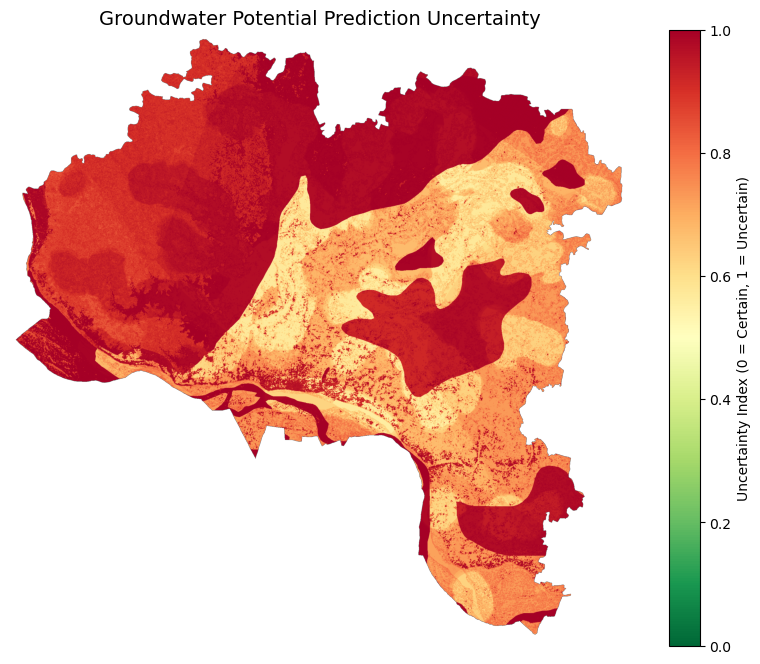

✓ Uncertainty map generated successfully.
Saved at: D:\Thesis\Main\Models\Random Forest\New Final\Results\Prediction_Uncertainty_Map11.tif


In [8]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ===============================
# 1. LOAD PROBABILITY MAPS
# ===============================

prob_low_path = r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Prob_Low11.tif'
prob_high_path = r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Prob_High11.tif'

with rasterio.open(prob_low_path) as src:
    prob_low = src.read(1)
    meta = src.meta.copy()

with rasterio.open(prob_high_path) as src:
    prob_high = src.read(1)

# ===============================
# 2. STACK PROBABILITIES
# ===============================

prob_stack = np.stack([prob_low, prob_high], axis=0)

# ===============================
# 3. SHANNON ENTROPY
# ===============================

epsilon = 1e-10
entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)

# Normalize for 2 classes
max_entropy = np.log(2)
normalized_entropy = entropy / max_entropy

# ===============================
# 4. HANDLE NODATA
# ===============================

nodata_value = meta.get('nodata', -9999)

mask = (prob_low == nodata_value)
normalized_entropy[mask] = nodata_value

meta.update(dtype='float32', nodata=nodata_value)

# ===============================
# 5. SAVE OUTPUT
# ===============================

output_path = r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Prediction_Uncertainty_Map11.tif'

with rasterio.open(output_path, 'w', **meta) as dst:
    dst.write(normalized_entropy.astype(np.float32), 1)

# ===============================
# 6. VISUALIZATION
# ===============================

plt.figure(figsize=(10, 8))
plt.imshow(np.where(normalized_entropy == nodata_value, np.nan, normalized_entropy),
           cmap='RdYlGn_r', vmin=0, vmax=1)
plt.colorbar(label='Uncertainty Index (0 = Certain, 1 = Uncertain)')
plt.title('Groundwater Potential Prediction Uncertainty', fontsize=14)
plt.axis('off')

plt.savefig(r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Uncertainty_Map_Final11.png', dpi=300)
plt.show()

print("✓ Uncertainty map generated successfully.")
print("Saved at:", output_path)
